# Can VLMs reject objects that are not present? (COCO)

Object hallucination in **Qwen2.5-VL-3B-Instruct**, measured with POPE-style yes/no object-existence questions on **COCO val2017**, with random, popular and adversarial negative sampling and three prompt formats.

This notebook walks through the COCO workflow uses. It does **not** run the model: it loads the logged
lmms-eval outputs in `results/raw/full/`, and calls `src/score_coco.py` and `src/analyze_coco.py` to
rebuild every table in `results/tables/coco/` and figure in `results/figures/coco/`.

**To run it:** use the `cmpe297` kernel and start Jupyter from the project folder. `CMPE297_DATA` must
point to the COCO images, which are only needed for the example images. Then choose
*Restart and Run All*.

In [1]:
import io
import json
import sys
from collections import Counter
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src" if Path.cwd().name == "notebooks" else Path.cwd() / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

import analyze_coco
import score_coco
from freeze_eval_set_coco import MANIFEST, verify
from parser import parse
from pope_sampling import SPLITS, image_path
from prompts import MAX_NEW_TOKENS, PROMPTS, build_prompt
from results_io import PROJECT, PROMPT_KINDS, RAW_DIR, load_predictions, load_questions, samples_file

import matplotlib.pyplot as plt
%matplotlib inline
analyze_coco.style()
plt.rcParams["savefig.dpi"] = plt.rcParams["figure.dpi"] = 110

DS = "coco"
TABLES, FIGURES = score_coco.TABLES, analyze_coco.FIGURES


def show_md(name):
    """Display a generated Markdown table without its file title (the section heading says what it is)."""
    text = (TABLES / name).read_text(encoding="utf-8")
    display(Markdown(text.split("\n", 1)[1] if text.startswith("# ") else text))


def show_fig(name, width=700, photo=False):
    """Display a figure from results/figures/coco/, downscaled for embedding (the file itself is unchanged)."""
    img = PILImage.open(FIGURES / name).convert("RGB")
    img.thumbnail((2 * width, 4 * width))
    buf = io.BytesIO()
    img.save(buf, format="JPEG" if photo else "PNG", **({"quality": 85} if photo else {"optimize": True}))
    display(Image(data=buf.getvalue(), format="jpeg" if photo else "png", width=width))


def run(main):
    """Call a script's main() as if run from the command line with its defaults."""
    argv, sys.argv = sys.argv, [main.__module__]
    try:
        main()
    finally:
        sys.argv = argv


problems = verify()
print("Frozen evaluation set matches MANIFEST.json." if not problems else problems)

Frozen evaluation set matches MANIFEST.json.


## 1. Research question and setup

**Research question.** When a vision-language model is asked whether an object is in an image, how
often does it say *yes* to an object that is not there? How does that rate change with:
- how the absent object is chosen (random vs frequent vs co-occurring);
- the prompt wording, including a prompt that explicitly allows "not sure"?

**Setup.**
- **Model:** one model, Qwen2.5-VL-3B-Instruct, bf16, with greedy decoding.
- **Questions:** 500 COCO images, 6 questions per image per split, 50/50 yes/no.
- **Prompts:** three predeclared prompts with the same output-token budget.
- **Parsing:** one fixed response parser.

The table below is the run metadata recorded for each of the three full COCO runs.

In [2]:
run_info = pd.DataFrame(json.loads(line) for line in open(RAW_DIR / "run_info.jsonl"))
run_info = run_info[run_info.task.str.startswith(f"pope_{DS}_")].reset_index(drop=True)
run_info["minutes"] = ((pd.to_datetime(run_info.end_utc) - pd.to_datetime(run_info.start_utc))
                       .dt.total_seconds() / 60).round(1)
display(run_info[["task", "start_utc", "minutes", "model", "model_revision", "lmms_eval", "transformers", "torch", "gpu"]])
print(f"max_new_tokens = {MAX_NEW_TOKENS} for every prompt; total inference time "
      f"{run_info.minutes.sum() / 60:.1f} h for {9000 * len(run_info):,} generations")

,task,start_utc,minutes,model,model_revision,lmms_eval,transformers,torch,gpu
0,pope_coco_ordinary,2026-11-16T04:10:26Z,23.0,Qwen/Qwen2.5-VL-3B-Instruct,66285546d2b821cf421d4f5eb2576359d3770cd3,0.7.4,5.23.0,2.6.0+cu124,NVIDIA GeForce RTX 4080
1,pope_coco_neutral,2026-11-16T04:33:27Z,23.0,Qwen/Qwen2.5-VL-3B-Instruct,66285546d2b821cf421d4f5eb2576359d3770cd3,0.7.4,5.23.0,2.6.0+cu124,NVIDIA GeForce RTX 4080
2,pope_coco_evidence,2026-11-16T04:56:25Z,24.2,Qwen/Qwen2.5-VL-3B-Instruct,66285546d2b821cf421d4f5eb2576359d3770cd3,0.7.4,5.23.0,2.6.0+cu124,NVIDIA GeForce RTX 4080


max_new_tokens = 16 for every prompt; total inference time 1.2 h for 27,000 generations


## 2. Dataset

**COCO val2017.** Ground truth comes from the instance annotations: 80 categories, exhaustively
labelled.
- The questions are rebuilt with our own builder (`src/build_pope_coco.py`).

In [3]:
manifest = json.loads(MANIFEST.read_text())
entry = manifest["files"][f"{DS}_pope.jsonl"]
rows = []
for split in SPLITS:
    yes, no = entry["counts"][f"{split}/yes"], entry["counts"][f"{split}/no"]
    rows.append({"images": entry["images"], "split": split, "yes": yes, "no": no,
                 "class balance (yes share)": f"{yes / (yes + no):.0%}"})
display(pd.DataFrame(rows))
print("frozen", manifest["frozen_utc"], "|", f"{DS}_pope.jsonl: {entry['rows']:,} rows, sha256 {entry['sha256'][:12]}...")

,images,split,yes,no,class balance (yes share)
0,500,random,1500,1500,50%
1,500,popular,1500,1500,50%
2,500,adversarial,1500,1500,50%


frozen 2026-11-16T03:44:37+00:00 | coco_pope.jsonl: 9,000 rows, sha256 2b006095bc7d...


**Object frequency.** These are the objects asked about most often as positives, i.e. the most
frequent objects in the 500 selected images. Popular negatives are drawn from the top of this list.

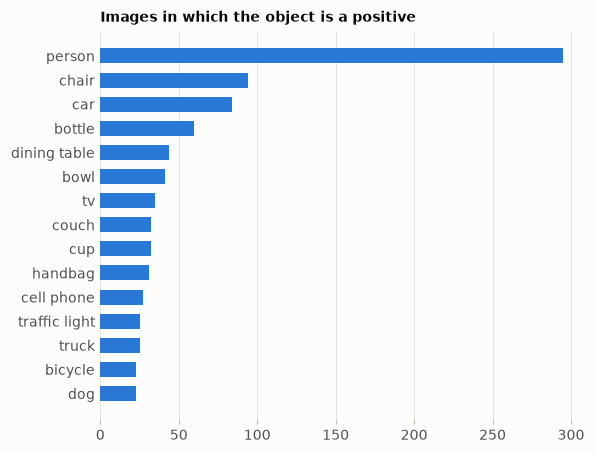

In [4]:
questions = load_questions(DS)
freq = Counter(q["object"] for q in questions if q["answer"] == "yes" and q["category"] == "random")
top = freq.most_common(15)[::-1]
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.barh([o for o, _ in top], [n for _, n in top], height=0.62, color=analyze_coco.PROMPT_COLOR["ordinary"])
ax.set_title("Images in which the object is a positive", loc="left", fontsize=9)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=analyze_coco.INK2)
ax.spines["bottom"].set_visible(False)
fig.tight_layout()
plt.show()

**Example image.** The first image of the set, shown with its three positive objects. Positives are the
first three annotated objects, in annotation order.

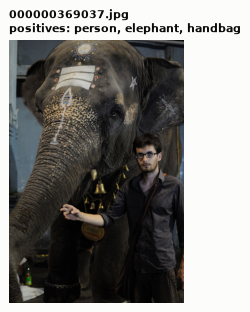

In [5]:
q0 = questions[0]
objs = [q["object"] for q in questions if q["image"] == q0["image"] and q["answer"] == "yes" and q["category"] == "random"]
fig, ax = plt.subplots(figsize=(5, 3.8), dpi=90)
ax.imshow(PILImage.open(image_path(analyze_coco.DATA_ROOT, DS, q0["image"])))
ax.set_title(f"{q0['image']}\npositives: {', '.join(objs)}", loc="left", fontsize=9)
ax.axis("off")
plt.show()

## 3. Question construction

The sampler is `src/pope_sampling.py`, which follows the official POPE code. Each positive is paired
with one negative per split, always an object with **no** annotation in the image:
- **random:** a uniformly random absent object;
- **popular:** the most frequent absent objects in the selected images;
- **adversarial:** the absent object that co-occurs most often with that positive.

Each negative also stores `cooc_score`, the mean probability of the probe given the image's annotated
objects, and `freq_rank`. The effect studies (section 8) group by these.

Below is a worked example for the first image.

In [6]:
ex = pd.DataFrame([q for q in questions if q["image"] == q0["image"]])
display(ex.pivot_table(index="category", columns="answer", values="object",
                       aggfunc=lambda s: ", ".join(s)).reindex(list(SPLITS)))
display(ex[ex.answer == "no"][["category", "object", "question", "cooc_score", "freq_rank"]])

answer,no,yes
category,,
random,"bus, sandwich, stop sign","person, elephant, handbag"
popular,"chair, dining table, car","person, elephant, handbag"
adversarial,"chair, car, backpack","person, elephant, handbag"


,category,object,question,cooc_score,freq_rank
1,random,bus,Is there a bus in the image?,0.021295,33
3,random,sandwich,Is there a sandwich in the image?,0.041293,29
5,random,stop sign,Is there a stop sign in the image?,0.007086,61
7,popular,chair,Is there a chair in the image?,0.147498,2
9,popular,dining table,Is there a dining table in the image?,0.133138,3
11,popular,car,Is there a car in the image?,0.227563,4
13,adversarial,chair,Is there a chair in the image?,0.147498,2
15,adversarial,car,Is there a car in the image?,0.227563,4
17,adversarial,backpack,Is there a backpack in the image?,0.114104,9


## 4. Prompts and parser

The three prompts are predeclared in `src/prompts.py`, the single source of truth. Every prompt is
built from the stored object name and gets the same `max_new_tokens`.
- **ordinary** mirrors standard POPE.
- **neutral** offers both outcomes symmetrically, to reduce acquiescence.
- **evidence** asks for visible evidence and is the only prompt that allows "not sure".

In [7]:
display(pd.DataFrame({"prompt": list(PROMPTS), "text (object = dog)": [build_prompt(k, "dog") for k in PROMPTS]})
        .style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,prompt,text (object = dog)
0,ordinary,Is there a dog in the image? Answer with yes or no.
1,neutral,"Does the image contain a dog, or does it not? Answer with yes or no."
2,evidence,"Look at the image carefully and answer based only on what is visibly present. Is there a dog in the image? Answer ""yes"" only if you can clearly see it. If it is not visible, answer ""no"". If you cannot tell, answer ""not sure""."


**The fixed parser.** `src/parser.py` maps each response to `yes`, `no`, `abstain` or `invalid`. It was
written once, unit-tested (`tests/test_coco.py`) and never tuned on results. Here it is on a few test
cases, then on every raw response from the full runs.

In [8]:
cases = ["Yes", "yes.", "Yes, there is a dog.", "No", "no, there isn't", "Not sure", "not visible",
         "", "There is a dog in the image."]
display(pd.DataFrame({"response": [repr(c) for c in cases], "parsed": [parse(c) for c in cases]}))

preds = {p: load_predictions(DS, p) for p in PROMPT_KINDS}
resp = pd.DataFrame([{"prompt": p, "raw response": v["response"].strip(), "parsed": v["prediction"]}
                     for p, d in preds.items() for v in d.values()])
display(resp.groupby(["prompt", "raw response", "parsed"]).size().rename("count").reset_index())
print("invalid parses:", int((resp.parsed == "invalid").sum()), "of", len(resp))

,response,parsed
0,'Yes',yes
1,'yes.',yes
2,"'Yes, there is a dog.'",yes
3,'No',no
4,"""no, there isn't""",no
5,'Not sure',abstain
6,'not visible',no
7,'',invalid
8,'There is a dog in the image.',invalid


,prompt,raw response,parsed,count
0,evidence,No,no,2
1,evidence,Yes,yes,139
2,evidence,no,no,1897
3,evidence,not sure,abstain,2681
4,evidence,yes,yes,4281
5,neutral,No,no,59
6,neutral,No.,no,126
7,neutral,Yes.,yes,473
8,neutral,no,no,4723
9,neutral,yes,yes,3619


invalid parses: 0 of 27000


## 5. Inference

The model was run with lmms-eval (`qwen2_5_vl` wrapper) on the three COCO tasks rendered by
`src/make_task_yamls_coco.py`, using `src/run_all_coco.sh`:

```bash
python -m lmms_eval --model qwen2_5_vl --model_args pretrained=Qwen/Qwen2.5-VL-3B-Instruct \
  --include_path "$PROJ/tasks/pope_custom" --tasks pope_coco_<prompt> \
  --batch_size 1 --log_samples --output_path "$PROJ/results/raw/full/"
```

The settings are greedy decoding, `max_new_tokens` 16 and batch size 1, with the wrapper's default
image resolution: no COCO image is downscaled.

Every score below comes from the logged per-question responses, re-parsed with the fixed parser and
joined to the frozen set by `question_id`. The check below confirms that each samples file has exactly
one response for each of the 9,000 questions.

In [9]:
ids = {q["question_id"] for q in questions}
check = [{"task": f"pope_{DS}_{p}", "samples file": samples_file(DS, p).name, "responses": len(preds[p]),
          "missing ids": len(ids - set(preds[p])), "unknown ids": len(set(preds[p]) - ids)}
         for p in PROMPT_KINDS]
display(pd.DataFrame(check))

,task,samples file,responses,missing ids,unknown ids
0,pope_coco_ordinary,20261116_121034_samples_pope_coco_ordinary.jsonl,9000,0,0
1,pope_coco_neutral,20261116_123332_samples_pope_coco_neutral.jsonl,9000,0,0
2,pope_coco_evidence,20261116_125630_samples_pope_coco_evidence.jsonl,9000,0,0


## 6. Label audit

Annotations can be incomplete, so a "no" label may be wrong. The audit has two stages, with one
reviewer per item (`src/audit_tool.py`, `notebooks/label_audit_coco.ipynb`).
- **Stage A (blind, predeclared).** `src/sample_audit_coco.py` drew the sample before any model output
  was looked at: 150 positives and 150 negatives (50 per split), seed 297.
  - The reviewer saw only the image and the object name, and answered *present*, *absent* or
    *uncertain*.
- **Stage B (not blind).** `src/sample_stage_b_coco.py` drew the lists, seed 297:
  - 100 ordinary-prompt false positives, each tagged with the error taxonomy.
  - 50 false negatives.

The audit never edits the frozen file. Verdicts are joined at scoring time.

The next cell rebuilds every table and figure from the logged outputs, the frozen set and the audit
labels: `score_coco.py` first (metrics, bootstrap CIs, audit views), then `analyze_coco.py` (effect
studies and figures).

In [10]:
run(score_coco.main)
run(analyze_coco.main)

wrote results/tables/coco/: metrics_long.csv (36 rows), split_comparison.csv, metrics_full_original.md, metrics_headline_ci.md, split_comparison.md, metrics_audited.md, label_quality.md


wrote results/tables/coco/: effect_size, effect_cooc, prompt_flips, top_objects (.csv + .md)
wrote results/figures/coco/: fig_examples_fp.png, fig_examples_label_error.png, fig_fpr_by_cooc.png, fig_fpr_by_split.png, fig_prompt_comparison.png, fig_recall_by_size.png


**Stage A sample design** (from `data/audit/audit_sample_coco.csv`):

In [11]:
design = pd.read_csv(PROJECT / f"data/audit/audit_sample_{DS}.csv")
display(design.groupby(["answer", "drawn_from"]).size().rename("questions").to_frame())

questions
answer drawn_from            
no     adversarial         50
       popular             50
       random              50
yes    positive           150

**Label-quality summary (view c).** This shows how often the reviewer disagreed with the dataset label,
and the share of reviewed model errors that were really label errors.

In [12]:
show_md("label_quality.md")

Stage A: blind single-reviewer verdicts on the predeclared audit sample. Stage B: reviewed ordinary-prompt errors (not blind: reviewers know each item is a model error).

| Items | Judged present | Judged absent | Judged uncertain |
|---|---|---|---|
| Stage A negatives (dataset says *no*), n=150 | 6 (4.0%) | 140 (93.3%) | 4 (2.7%) |
| Stage A positives (dataset says *yes*), n=150 | 140 (93.3%) | 2 (1.3%) | 8 (5.3%) |

| Stage B list | Reviewed | Tagged *label error* |
|---|---|---|
| Ordinary-prompt false positives | 100 | 20 (20.0%) |
| Ordinary-prompt false negatives | 50 | 15 (30.0%) |

| Stage B false-positive tag | Count |
|---|---|
| similar object | 52 |
| co-occurrence prior | 23 |
| label error | 20 |
| other / no visible cause | 5 |

| Stage B false-negative tag | Count |
|---|---|
| small | 15 |
| label error | 15 |
| occluded or truncated | 14 |
| unusual appearance | 6 |


## 7. Results

### 7.1 Main metrics (view a: full set, original labels)

These metrics follow the POPE definitions. Abstentions are never counted as correct.
- **Hallucination rate:** the false-positive rate, i.e. *yes* on an absent object.
- **Recall:** computed over all positives.

In [13]:
show_md("metrics_full_original.md")

All metrics in %. N = 3,000 per split (1,500 yes / 1,500 no, class balance 50%); "all" pools the three splits (N = 9,000). Abstain counts abstentions plus invalid parses (invalid parses are listed in metrics_long.csv).

| Prompt | Split | Acc | Prec | Rec | F1 | Spec | Halluc (FPR) | FNR | Yes ratio | Abstain | Abst. pos | Abst. neg |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ordinary | random | 92.6 | 99.1 | 86.1 | 92.1 | 99.2 | 0.8 | 13.9 | 43.4 | 0.0 | 0.0 | 0.0 |
| ordinary | popular | 91.2 | 95.9 | 86.1 | 90.7 | 96.3 | 3.7 | 13.9 | 44.9 | 0.0 | 0.0 | 0.0 |
| ordinary | adversarial | 90.2 | 93.8 | 86.1 | 89.7 | 94.3 | 5.7 | 13.9 | 45.9 | 0.0 | 0.0 | 0.0 |
| ordinary | all | 91.3 | 96.2 | 86.1 | 90.9 | 96.6 | 3.4 | 13.9 | 44.7 | 0.0 | 0.0 | 0.0 |
| neutral | random | 93.4 | 99.2 | 87.5 | 93.0 | 99.3 | 0.7 | 12.5 | 44.1 | 0.0 | 0.0 | 0.0 |
| neutral | popular | 92.0 | 96.2 | 87.5 | 91.7 | 96.5 | 3.5 | 12.5 | 45.5 | 0.0 | 0.0 | 0.0 |
| neutral | adversarial | 90.7 | 93.5 | 87.5 | 90.4 | 93.9 | 6.1 | 12.5 | 46.8 | 0.0 | 0.0 | 0.0 |
| neutral | all | 92.1 | 96.3 | 87.5 | 91.7 | 96.6 | 3.4 | 12.5 | 45.5 | 0.0 | 0.0 | 0.0 |
| evidence | random | 64.2 | 97.9 | 91.9 | 94.8 | 36.5 | 1.9 | 4.1 | 46.9 | 32.8 | 4.1 | 61.5 |
| evidence | popular | 64.5 | 93.6 | 91.9 | 92.7 | 37.1 | 6.3 | 4.1 | 49.1 | 30.3 | 4.1 | 56.6 |
| evidence | adversarial | 66.3 | 89.5 | 91.9 | 90.7 | 40.8 | 10.8 | 4.1 | 51.3 | 26.2 | 4.1 | 48.4 |
| evidence | all | 65.0 | 93.5 | 91.9 | 92.7 | 38.1 | 6.4 | 4.1 | 49.1 | 29.8 | 4.1 | 55.5 |


### 7.2 Headline metrics with 95% CIs

The intervals come from a percentile bootstrap over **images** (1,000 resamples, seed 297). Images are
resampled because the six questions about one image are not independent.

In [14]:
show_md("metrics_headline_ci.md")

Full set, original labels. Point estimate [95% CI] in %, percentile bootstrap over images (1,000 resamples, seed 297).

| Prompt | Split | Accuracy | F1 | Halluc (FPR) | FNR |
|---|---|---|---|---|---|
| ordinary | random | 92.6 [91.7, 93.5] | 92.1 [91.1, 93.1] | 0.8 [0.4, 1.2] | 13.9 [12.2, 15.5] |
| ordinary | popular | 91.2 [90.1, 92.2] | 90.7 [89.6, 91.8] | 3.7 [2.7, 4.7] | 13.9 [12.2, 15.5] |
| ordinary | adversarial | 90.2 [89.2, 91.2] | 89.7 [88.7, 90.9] | 5.7 [4.7, 6.8] | 13.9 [12.2, 15.5] |
| ordinary | all | 91.3 [90.4, 92.3] | 90.9 [89.8, 91.9] | 3.4 [2.8, 4.0] | 13.9 [12.2, 15.5] |
| neutral | random | 93.4 [92.6, 94.3] | 93.0 [92.1, 94.0] | 0.7 [0.3, 1.1] | 12.5 [10.9, 14.1] |
| neutral | popular | 92.0 [91.1, 93.0] | 91.7 [90.7, 92.7] | 3.5 [2.6, 4.4] | 12.5 [10.9, 14.1] |
| neutral | adversarial | 90.7 [89.8, 91.8] | 90.4 [89.4, 91.5] | 6.1 [5.0, 7.2] | 12.5 [10.9, 14.1] |
| neutral | all | 92.1 [91.2, 93.0] | 91.7 [90.7, 92.7] | 3.4 [2.8, 4.0] | 12.5 [10.9, 14.1] |
| evidence | random | 64.2 [62.7, 65.8] | 94.8 [94.0, 95.6] | 1.9 [1.2, 2.7] | 4.1 [3.1, 5.0] |
| evidence | popular | 64.5 [63.0, 65.9] | 92.7 [91.8, 93.7] | 6.3 [5.1, 7.5] | 4.1 [3.1, 5.0] |
| evidence | adversarial | 66.3 [64.9, 67.9] | 90.7 [89.7, 91.6] | 10.8 [9.3, 12.3] | 4.1 [3.1, 5.0] |
| evidence | all | 65.0 [63.8, 66.3] | 92.7 [91.9, 93.5] | 6.4 [5.5, 7.3] | 4.1 [3.1, 5.0] |


### 7.3 Do popular and adversarial negatives raise hallucination?

This is a paired bootstrap on the hallucination-rate difference: each resample scores both splits on
the same images.

Difference = second split minus first, in percentage points. 95% CI from a paired bootstrap over images (1,000 resamples, seed 297): each resample scores both splits on the same images. Significant = the interval excludes 0.

| Comparison | FPR first (%) | FPR second (%) | Difference (pp) | 95% CI (pp) | Significant |
|---|---|---|---|---|---|
| random vs popular | 0.8 | 3.7 | +2.9 | [+1.9, +3.9] | yes |
| random vs adversarial | 0.8 | 5.7 | +4.9 | [+3.8, +6.1] | yes |


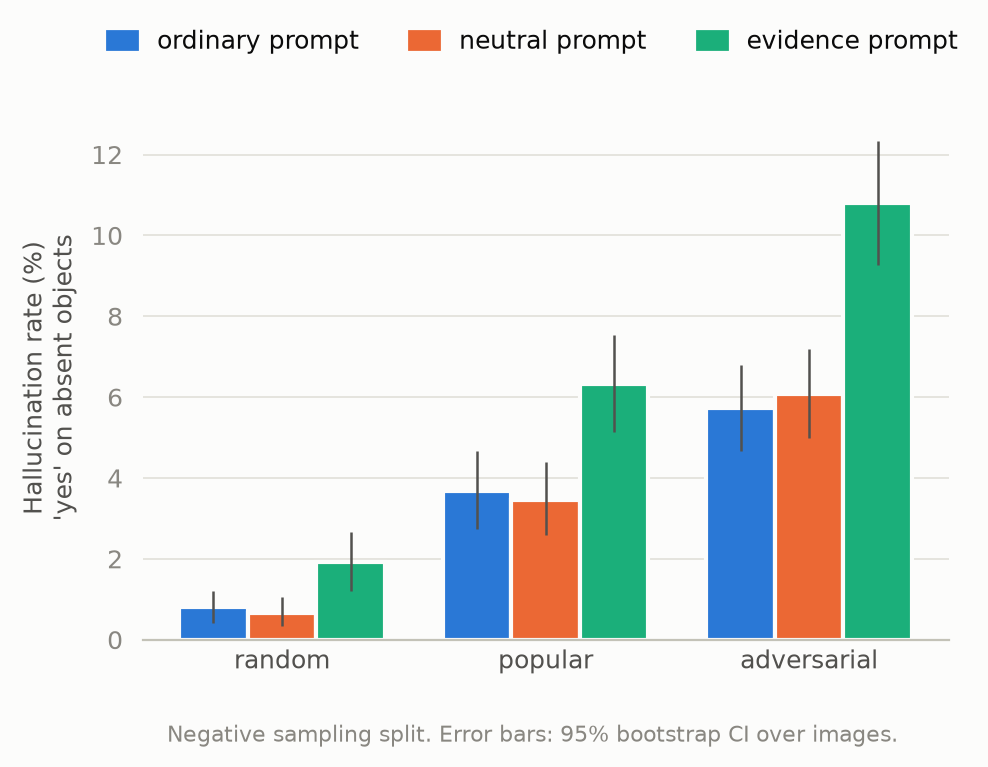

In [15]:
show_md("split_comparison.md")
show_fig("fig_fpr_by_split.png")

### 7.4 Audited subset with corrected labels (view b)

This view uses the 300 Stage A questions, scored twice: with the dataset labels and with
the reviewer's verdicts. Items judged uncertain are excluded from both.

In [16]:
show_md("metrics_audited.md")

The 300 audited questions (150 drawn as positives, 150 as negatives), each counted once. *original* scores them with the dataset labels, *corrected* with the reviewer's verdicts; items judged uncertain are excluded from both and counted in "Uncertain". All metrics in %. Per-split rows are in metrics_long.csv.

| Prompt | Labels | N | N pos | N neg | Uncertain | Acc | Prec | Rec | F1 | Spec | Halluc (FPR) | FNR | Yes ratio | Abstain | Abst. pos | Abst. neg |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ordinary | original | 288 | 142 | 146 | 12 | 92.4 | 99.2 | 85.2 | 91.7 | 99.3 | 0.7 | 14.8 | 42.4 | 0.0 | 0.0 | 0.0 |
| ordinary | corrected | 288 | 146 | 142 | 12 | 91.0 | 99.2 | 82.9 | 90.3 | 99.3 | 0.7 | 17.1 | 42.4 | 0.0 | 0.0 | 0.0 |
| neutral | original | 288 | 142 | 146 | 12 | 93.1 | 98.4 | 87.3 | 92.5 | 98.6 | 1.4 | 12.7 | 43.8 | 0.0 | 0.0 | 0.0 |
| neutral | corrected | 288 | 146 | 142 | 12 | 92.4 | 99.2 | 85.6 | 91.9 | 99.3 | 0.7 | 14.4 | 43.8 | 0.0 | 0.0 | 0.0 |
| evidence | original | 288 | 142 | 146 | 12 | 65.6 | 95.6 | 90.8 | 93.1 | 41.1 | 4.1 | 2.1 | 46.9 | 31.2 | 7.0 | 54.8 |
| evidence | corrected | 288 | 146 | 142 | 12 | 64.6 | 96.3 | 89.0 | 92.5 | 39.4 | 3.5 | 4.8 | 46.9 | 31.2 | 6.2 | 57.0 |


## 8. Effect studies

The unit here is **distinct** questions: a positive occurs in all three splits but is counted once.

### 8.1 Object size
This shows recall on present objects by the size of the object's largest instance, using COCO's area
thresholds.

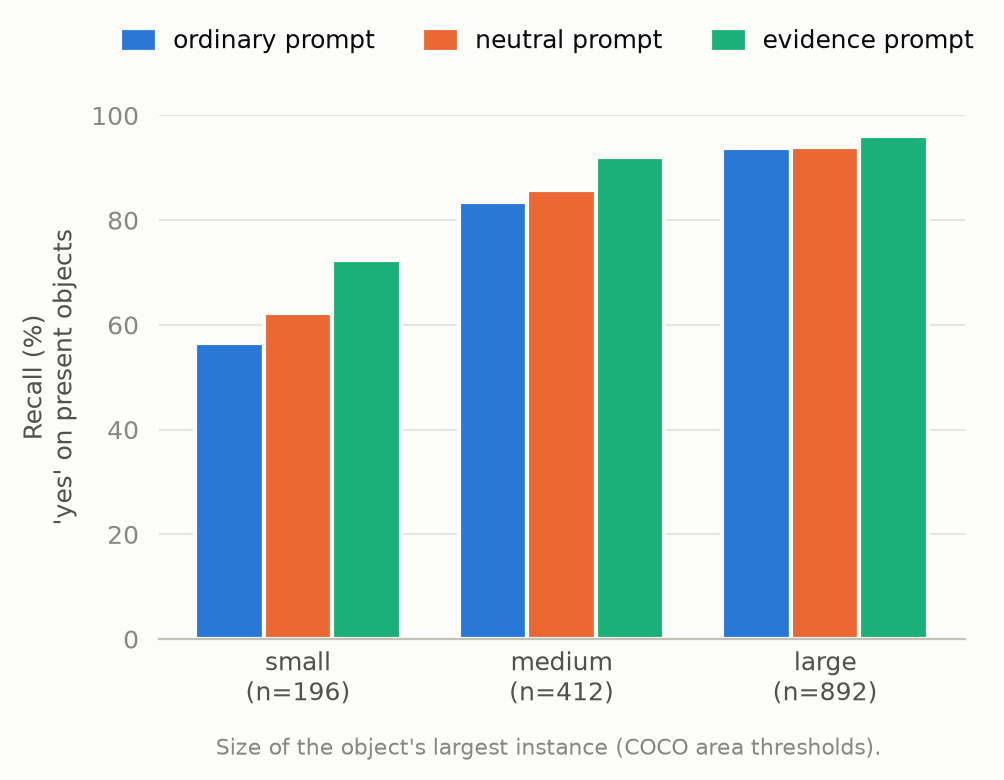

Distinct positive questions; size bin of the largest instance (COCO thresholds: small < 32², medium < 96² pixels). Recall + FNR + abstention = 100%. Rates in %.

| Prompt | Size | N | Recall | FNR | Abstain |
|---|---|---|---|---|---|
| ordinary | small | 196 | 56.6 | 43.4 | 0.0 |
| ordinary | medium | 412 | 83.5 | 16.5 | 0.0 |
| ordinary | large | 892 | 93.7 | 6.3 | 0.0 |
| neutral | small | 196 | 62.2 | 37.8 | 0.0 |
| neutral | medium | 412 | 85.7 | 14.3 | 0.0 |
| neutral | large | 892 | 93.9 | 6.1 | 0.0 |
| evidence | small | 196 | 72.4 | 9.7 | 17.9 |
| evidence | medium | 412 | 92.0 | 4.4 | 3.6 |
| evidence | large | 892 | 96.1 | 2.7 | 1.2 |


In [17]:
show_fig("fig_recall_by_size.png")
show_md("effect_size.md")

### 8.2 Co-occurrence and object frequency
This shows the hallucination rate of negatives by quartile of `cooc_score`, i.e. how strongly the
absent object is suggested by what is in the image. The frequency-rank bands follow.
- The *per-split* rows check whether co-occurrence still matters within one sampling strategy.
- If it does, co-occurrence, not the split label itself, drives the split effect.

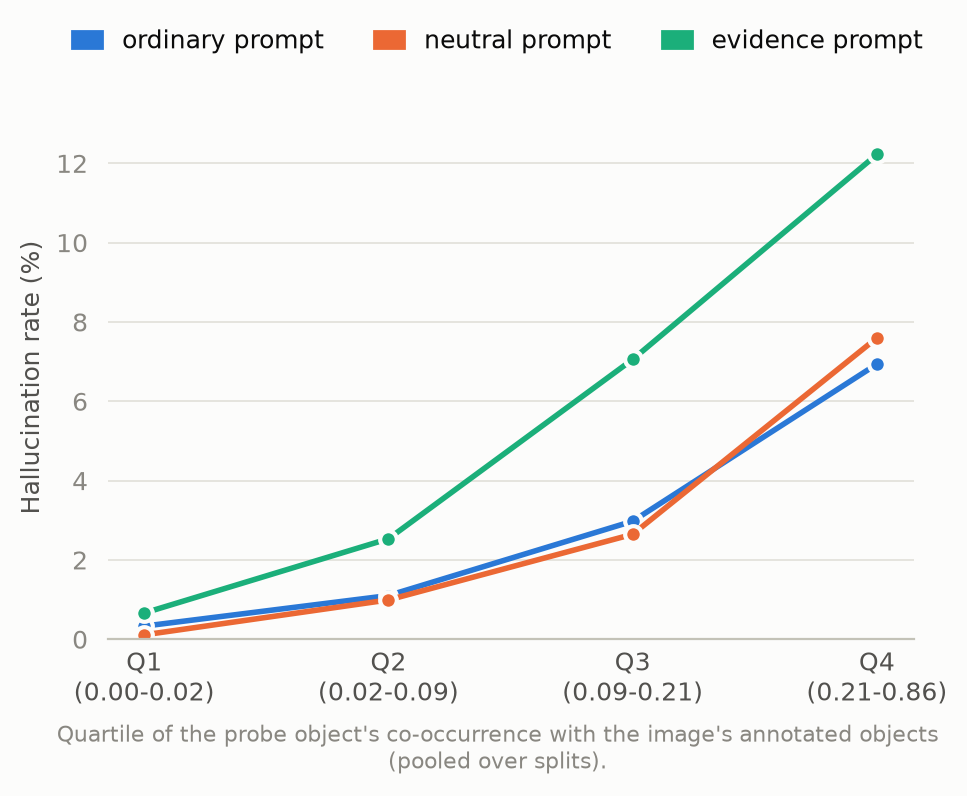

Hallucination rate (%) of negatives. *cooc_score* = mean over the image's annotated objects of P(probe object | that object); quartile edges from the pooled negatives. *freq_rank* = the probe object's frequency rank in the selected images (1 = most frequent). Pooled = each distinct question once. N per cell in effect_cooc.csv.

## By co-occurrence quartile

| Split | Prompt | Q1 (0.00-0.02) | Q2 (0.02-0.09) | Q3 (0.09-0.21) | Q4 (0.21-0.86) |
|---|---|---|---|---|---|
| pooled | ordinary | 0.3 (n=907) | 1.1 (n=908) | 3.0 (n=907) | 6.9 (n=908) |
| pooled | neutral | 0.1 (n=907) | 1.0 (n=908) | 2.6 (n=907) | 7.6 (n=908) |
| pooled | evidence | 0.7 (n=907) | 2.5 (n=908) | 7.1 (n=907) | 12.2 (n=908) |
| random | ordinary | 0.3 (n=876) | 1.1 (n=452) | 1.6 (n=125) | 4.3 (n=47) |
| random | neutral | 0.1 (n=876) | 0.9 (n=452) | 2.4 (n=125) | 4.3 (n=47) |
| random | evidence | 0.7 (n=876) | 2.7 (n=452) | 5.6 (n=125) | 8.5 (n=47) |
| popular | ordinary | 0.0 (n=31) | 0.7 (n=402) | 1.5 (n=459) | 7.4 (n=608) |
| popular | neutral | 0.0 (n=31) | 0.7 (n=402) | 0.7 (n=459) | 7.6 (n=608) |
| popular | evidence | 0.0 (n=31) | 1.7 (n=402) | 3.9 (n=459) | 11.5 (n=608) |
| adversarial | ordinary | 0.0 (n=1) | 2.2 (n=136) | 3.9 (n=584) | 7.7 (n=779) |
| adversarial | neutral | 0.0 (n=1) | 2.2 (n=136) | 3.8 (n=584) | 8.5 (n=779) |
| adversarial | evidence | 0.0 (n=1) | 3.7 (n=136) | 8.7 (n=584) | 13.6 (n=779) |

## By frequency rank

| Split | Prompt | 1-5 | 6-20 | 21-50 | 51+ |
|---|---|---|---|---|---|
| pooled | ordinary | 3.5 (n=1496) | 4.2 (n=787) | 1.6 (n=742) | 0.8 (n=605) |
| pooled | neutral | 3.4 (n=1496) | 4.4 (n=787) | 1.9 (n=742) | 0.5 (n=605) |
| pooled | evidence | 6.1 (n=1496) | 10.2 (n=787) | 3.4 (n=742) | 1.3 (n=605) |
| random | ordinary | 1.6 (n=62) | 1.1 (n=285) | 0.9 (n=573) | 0.5 (n=580) |
| random | neutral | 1.6 (n=62) | 1.1 (n=285) | 0.9 (n=573) | 0.2 (n=580) |
| random | evidence | 4.8 (n=62) | 3.2 (n=285) | 1.9 (n=573) | 1.0 (n=580) |
| popular | ordinary | 3.6 (n=1430) | 4.3 (n=70) | n/a (n=0) | n/a (n=0) |
| popular | neutral | 3.4 (n=1430) | 4.3 (n=70) | n/a (n=0) | n/a (n=0) |
| popular | evidence | 5.8 (n=1430) | 17.1 (n=70) | n/a (n=0) | n/a (n=0) |
| adversarial | ordinary | 5.8 (n=809) | 5.9 (n=491) | 4.6 (n=174) | 7.7 (n=26) |
| adversarial | neutral | 5.8 (n=809) | 6.5 (n=491) | 5.7 (n=174) | 7.7 (n=26) |
| adversarial | evidence | 9.5 (n=809) | 13.8 (n=491) | 8.6 (n=174) | 7.7 (n=26) |


In [18]:
show_fig("fig_fpr_by_cooc.png")
show_md("effect_cooc.md")

### 8.3 Question wording
This is how answers change between prompts. The key question: does permission to abstain remove
hallucinations, or correct answers?

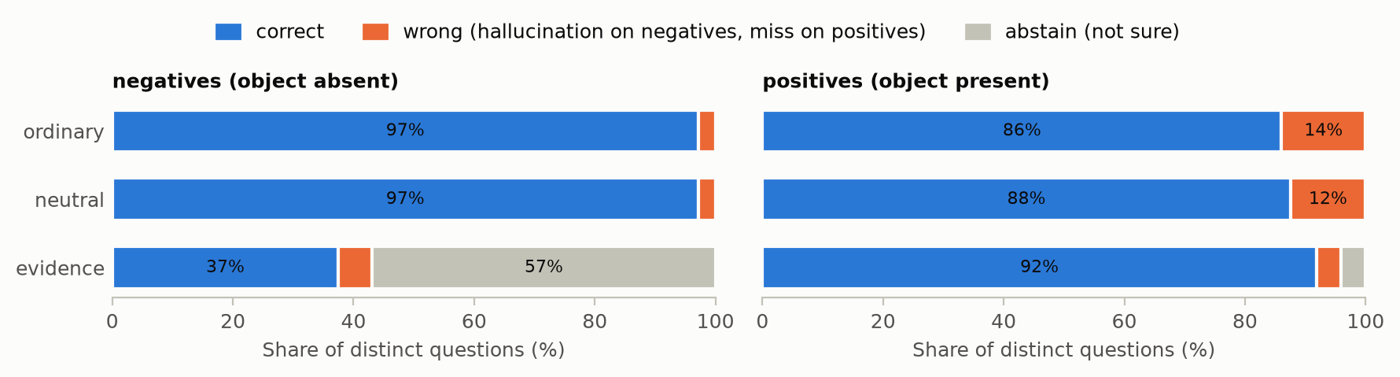

Distinct questions whose parsed answer differs between two prompts (invalid parses count as abstentions). Full transition counts in prompt_flips.csv.

| Prompts | Questions | N | Answer changed |
|---|---|---|---|
| ordinary vs neutral | positives | 1500 | 48 (3.2%) |
| ordinary vs neutral | negatives | 3630 | 36 (1.0%) |
| ordinary vs evidence | positives | 1500 | 152 (10.1%) |
| ordinary vs evidence | negatives | 3630 | 2173 (59.9%) |
| neutral vs evidence | positives | 1500 | 138 (9.2%) |
| neutral vs evidence | negatives | 3630 | 2179 (60.0%) |

## Where the ordinary prompt's answers go under the evidence prompt

Does permission to abstain remove hallucinations, or correct answers? Counts of distinct questions.

| Ordinary answer | N | Evidence: yes | Evidence: no | Evidence: not sure |
|---|---|---|---|---|
| negatives: ordinary *yes* (hallucination) | 103 | 99 (96.1%) | 3 (2.9%) | 1 (1.0%) |
| negatives: ordinary *no* (correct) | 3527 | 105 (3.0%) | 1358 (38.5%) | 2064 (58.5%) |
| positives: ordinary *yes* (correct) | 1291 | 1289 (99.8%) | 2 (0.2%) | 0 (0.0%) |
| positives: ordinary *no* (miss) | 209 | 89 (42.6%) | 59 (28.2%) | 61 (29.2%) |


In [19]:
show_fig("fig_prompt_comparison.png")
show_md("prompt_flips.md")

### 8.4 Category-specific errors (ordinary prompt)

In [20]:
show_md("top_objects.md")

Top objects by number of errors over distinct questions; rate = errors / questions about that object with that label.

## Most hallucinated (answered yes, labelled no)

| # | Object | Errors | N | Rate (%) |
|---|---|---|---|---|
| 1 | dining table | 32 | 402 | 8.0 |
| 2 | chair | 16 | 377 | 4.2 |
| 3 | handbag | 8 | 91 | 8.8 |
| 4 | backpack | 7 | 60 | 11.7 |
| 5 | truck | 5 | 81 | 6.2 |
| 6 | bowl | 4 | 73 | 5.5 |
| 7 | bottle | 4 | 111 | 3.6 |
| 8 | knife | 3 | 38 | 7.9 |
| 9 | car | 3 | 352 | 0.9 |
| 10 | potted plant | 2 | 20 | 10.0 |

## Most missed (answered no, labelled yes)

| # | Object | Errors | N | Rate (%) |
|---|---|---|---|---|
| 1 | chair | 21 | 94 | 22.3 |
| 2 | person | 19 | 295 | 6.4 |
| 3 | car | 16 | 84 | 19.0 |
| 4 | cup | 14 | 32 | 43.8 |
| 5 | backpack | 9 | 23 | 39.1 |
| 6 | bowl | 8 | 41 | 19.5 |
| 7 | bench | 7 | 18 | 38.9 |
| 8 | dining table | 7 | 44 | 15.9 |
| 9 | bottle | 7 | 60 | 11.7 |
| 10 | knife | 5 | 16 | 31.2 |


## 9. Error taxonomy and qualitative examples

These are the Stage B tags for the reviewed ordinary-prompt errors.
- **False positives:** each is either a label error (the object is actually present) or a genuine
  hallucination, with its likely cause.
- **False negatives:** each is a label error or a real miss, with its cause.

In [21]:
tags = []
for kind in ("fp", "fn"):
    items = score_coco.stage_b(kind)
    for tag, n in Counter(it["tag"] for it in items).most_common():
        tags.append({"list": {"fp": "false positives", "fn": "false negatives"}[kind], "tag": tag,
                     "count": n, "share": n / len(items)})
display(pd.DataFrame(tags).set_index(["list", "tag"]).style.format({"share": "{:.0%}"}))

**Unsupported "yes" answers.** These are ordinary-prompt false positives that the reviewer confirmed
absent, with their taxonomy tags. The ids are fixed in `analyze_coco.EXAMPLES_FP`.

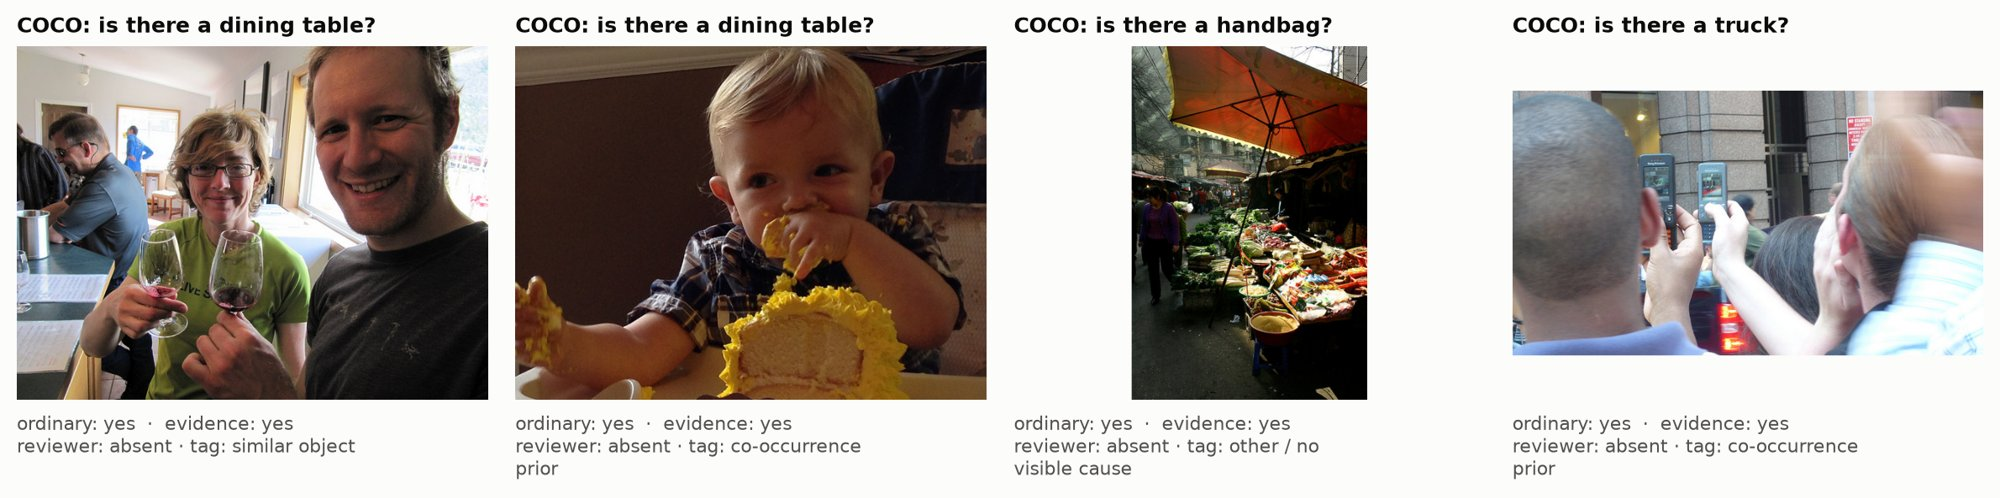

In [22]:
show_fig("fig_examples_fp.png", width=1000, photo=True)

**Label errors.** These are ordinary-prompt "false positives" where the object is actually present. The
dataset label is wrong, not the model.

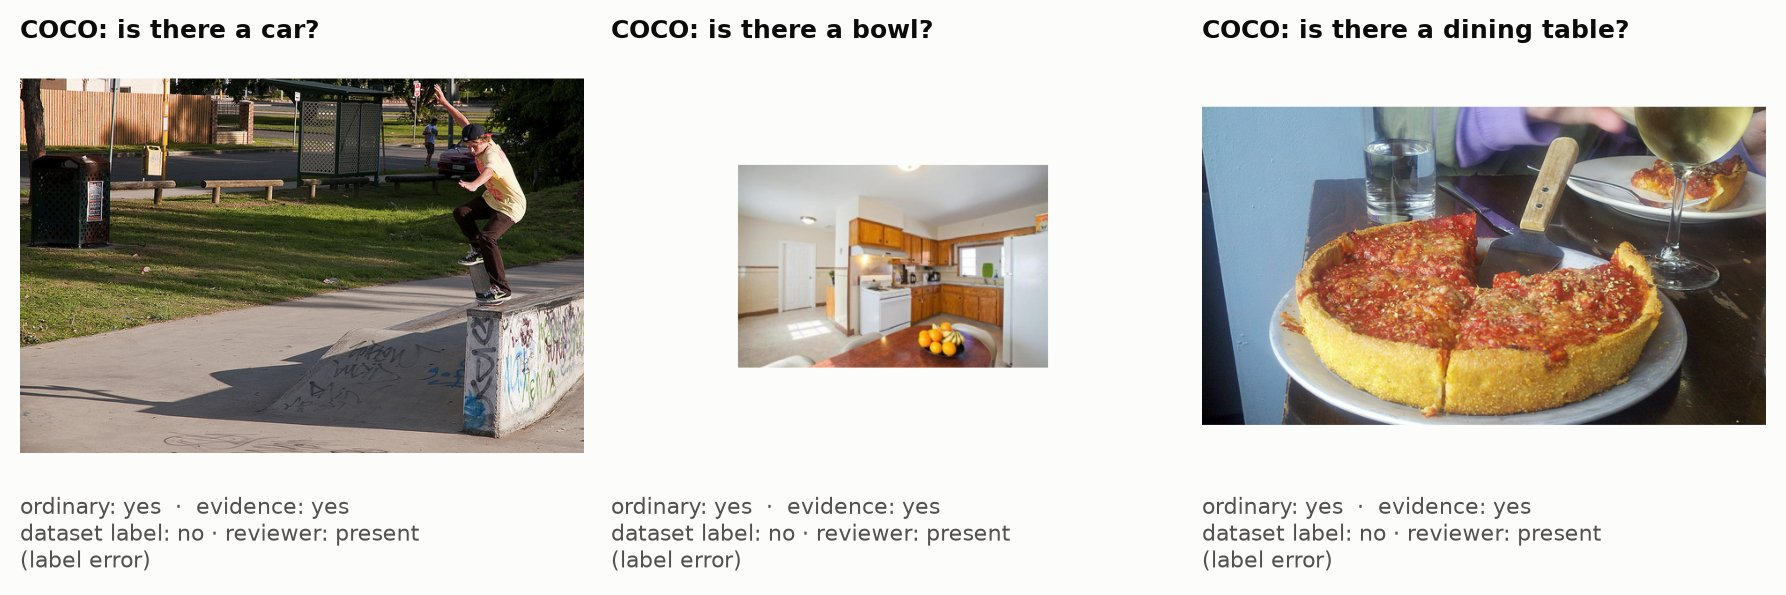

In [23]:
show_fig("fig_examples_label_error.png", width=900, photo=True)

## 10. Conclusions and limitations

The key numbers below are computed from the generated tables, so they always match them.

In [24]:
long = pd.read_csv(TABLES / "metrics_long.csv")
full = long[long.label_view == "full_original"].set_index(["prompt", "split"])
c = pd.read_csv(TABLES / "split_comparison.csv").set_index("split_b")
flips = pd.read_csv(TABLES / "prompt_flips.csv")
cooc = pd.read_csv(TABLES / "effect_cooc.csv")
size = pd.read_csv(TABLES / "effect_size.csv").set_index(["prompt", "size_bin"])
Q = score_coco.label_quality(score_coco.stage_a())
aud = long[(long.split == "all") & long.label_view.str.startswith("audit_")].set_index(["prompt", "label_view"])


def p(x):
    return f"{100 * x:.1f}%"


lines = []
o = full.loc["ordinary", "all"]
lines.append(f"- **Ordinary prompt:** accuracy {p(o.accuracy)}, F1 {p(o.f1)}; hallucination rate "
             f"{p(full.loc['ordinary', 'random'].hallucination_rate)} (random), "
             f"{p(full.loc['ordinary', 'popular'].hallucination_rate)} (popular), "
             f"{p(full.loc['ordinary', 'adversarial'].hallucination_rate)} (adversarial). "
             f"Popular and adversarial negatives raise it by {100 * c.loc['popular', 'difference']:+.1f} and "
             f"{100 * c.loc['adversarial', 'difference']:+.1f} pp, "
             f"{'both' if c.significant.all() else 'not both'} significant. "
             f"False-negative rate {p(o.fn_rate)}"
             + (": the model misses present objects more often than it invents absent ones." if o.fn_rate > o.hallucination_rate
                else "."))
f = flips[(flips.dataset == DS) & (flips.prompt_a == "ordinary") & (flips.prompt_b == "evidence")].set_index("label")
neg = f.loc["no"]
kept = neg["yes->yes"] / (neg["yes->yes"] + neg["yes->no"] + neg["yes->abstain"])
lost = neg["no->abstain"] / (neg["no->yes"] + neg["no->no"] + neg["no->abstain"])
lines.append(f"- **Evidence prompt:** {p(kept)} of the ordinary prompt's hallucinations stay *yes*, while "
             f"{p(lost)} of its correct *no* answers become \"not sure\". Hallucination rate "
             f"{p(full.loc['evidence', 'all'].hallucination_rate)} vs {p(o.hallucination_rate)} (ordinary)."
             + (" Permission to abstain mostly removes correct rejections, not hallucinations." if kept > 0.5 and lost > 0.5
                else ""))
q = cooc[(cooc.dataset == DS) & (cooc.grouping == "cooc_quartile") & (cooc.split == "pooled") & (cooc.prompt == "ordinary")]
lines.append(f"- **Co-occurrence and size:** hallucination rate rises from {p(q.hallucination_rate.iloc[0])} "
             f"(lowest co-occurrence quartile) to {p(q.hallucination_rate.iloc[-1])} (highest); recall is "
             f"{p(size.loc['ordinary', 'small'].recall)} on small vs {p(size.loc['ordinary', 'large'].recall)} on large objects.")
a, b = aud.loc["ordinary", "audit_original"], aud.loc["ordinary", "audit_corrected"]
lines.append(f"- **Label quality:** {Q['neg']['present']} of {Q['n_neg']} audited negatives were actually present "
             f"({p(Q['neg']['present'] / Q['n_neg'])}), and {Q['fp']['label error']} of {Q['n_fp']} reviewed false positives "
             f"were label errors. On the audited subset, the ordinary prompt's hallucination rate is "
             f"{p(a.hallucination_rate)} with dataset labels and {p(b.hallucination_rate)} with corrected labels.")
display(Markdown("\n".join(lines)))

- **Ordinary prompt:** accuracy 91.3%, F1 90.9%; hallucination rate 0.8% (random), 3.7% (popular), 5.7% (adversarial). Popular and adversarial negatives raise it by +2.9 and +4.9 pp, both significant. False-negative rate 13.9%: the model misses present objects more often than it invents absent ones.
- **Evidence prompt:** 96.1% of the ordinary prompt's hallucinations stay *yes*, while 58.5% of its correct *no* answers become "not sure". Hallucination rate 6.4% vs 3.4% (ordinary). Permission to abstain mostly removes correct rejections, not hallucinations.
- **Co-occurrence and size:** hallucination rate rises from 0.3% (lowest co-occurrence quartile) to 6.9% (highest); recall is 56.6% on small vs 93.7% on large objects.
- **Label quality:** 6 of 150 audited negatives were actually present (4.0%), and 20 of 100 reviewed false positives were label errors. On the audited subset, the ordinary prompt's hallucination rate is 0.7% with dataset labels and 0.7% with corrected labels.

**Limitations:**
- **Audit size and design.**
  - The audit is small: 300 Stage A items and 150 Stage B items.
  - Each item has a single reviewer so there is no agreement measure.
  - Stage B is not blind.
- **Scope.**
  - One model with one sample of 500 images and one seed.
  - COCO's 80-category vocabulary limits which objects can be probed.
  - The prompt comparison is descriptive, with no significance tests between prompts.